# Solar Installation Duration — Model Analysis
**Goal:** Push R² above 0.55 through feature engineering and model selection.

Sections:
1. Setup & Data
2. Exploratory Data Analysis (EDA)
3. Feature Engineering
4. Model Comparison
5. Residual Analysis
6. Best Model Summary

In [1]:
# Install dependencies
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
    'scikit-learn', 'pandas', 'numpy', 'matplotlib', 'seaborn'])
print('Dependencies ready.')

Dependencies ready.


In [2]:
import io, os, pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import r2_score, mean_squared_error

pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.family'] = 'Arial'
RANDOM_STATE = 42
print('Imports done.')

Imports done.


## 1. Load Data
Full Working Data sheet — roof mounts only, 264 jobs, 30 columns. Drive time and salary hours converted to decimal hours.

In [3]:
DATA_PATH = 'data/solar_data_full.csv'

if not os.path.exists(DATA_PATH):
    from google.colab import files
    print('File not found — uploading now...')
    uploaded = files.upload()  # select solar_data_full.csv
    os.makedirs('data', exist_ok=True)
    import shutil
    shutil.move(list(uploaded.keys())[0], DATA_PATH)

df = pd.read_csv(DATA_PATH)

for col in ['Tilt', 'Azimuth', 'Panel QTY', 'System Rating (kW DC)',
            '# of Arrays', '# of reinforcement', '# of Stories',
            'Module Length', 'Module Width', 'Module Weight',
            'Estimated Total # of People on Site', 'Estimated Total Direct Time',
            'Total # of Days on Site', 'Estimated Salary Hours']:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

print('Shape:', df.shape)
df.head()

Shape: (264, 30)


,Project ID,Drive Time,Tilt,Azimuth,Panel QTY,System Rating (kW DC),Inverter Manufacturer,Squirrel Screen,Consumption Monitoring,Truss / Rafter,Reinforcements,Rough Electrical Inspection,Interconnection Type,Module Length,Module Width,Module Weight,# of Arrays,# of reinforcement,Roof Type,Attachment Type,Portrait / Landscape,# of Stories,Install Season,Total Direct Time for Project for Hourly Employees (Including Drive Time),Total # of Days on Site,Total # Hourly Empoyees on Site,Estimated # of Salaried Employees on Site,Estimated Salary Hours,Estimated Total Direct Time,Estimated Total # of People on Site
0,1,21 mins,33.0,180.0,19,6.84,SolarEdge,Yes,NaN,Truss,No,No,A1,67.8,40.0,43.0,1,0,Asphalt Shingles,Flashfoot 2,Portrait,2,Spring,19.0000,1,2,2,19.0000,38.0000,4
1,2,23 mins,45.0,139.0,18,6.57,SolarEdge,Yes,NaN,Rafter,Yes,Yes,A1,67.8,40.0,43.0,1,2,Asphalt Shingles,Flashfoot 2,Portrait,1,Spring,33.5000,2,2,2,33.5000,67.0000,4
2,3,21 mins,24.0,180.0,16,5.12,SolarEdge,No,NaN,Truss,No,No,A3,66.3,39.4,41.2,2,0,Asphalt Shingles,Flashfoot 2,Portrait,1,Spring,25.3333,2,2,2,25.3333,50.6667,4
3,4,38 mins,20.0,104.0,27,10.80,Enphase,No,NaN,Truss,No,No,C2,79.3,39.4,51.8,1,0,Asphalt Shingles,Flashfoot 2,Portrait,1,Spring,27.0000,2,2,2,27.0000,54.0000,4
4,5,38 mins,20.0,180.0,27,10.80,Enphase,No,NaN,Truss,No,No,C2,79.3,39.4,51.8,1,0,Asphalt Shingles,Flashfoot 2,Both,1,Spring,27.0000,2,2,2,27.0000,54.0000,4


In [4]:
print('Columns:')
for c in df.columns:
    print(' -', c)
print('\nNull counts:')
print(df.isnull().sum())
print('\nDescriptive stats:')
df.describe()

Columns:
 - Project ID
 - Drive Time
 - Tilt
 - Azimuth
 - Panel QTY
 - System Rating (kW DC)
 - Inverter Manufacturer
 - Squirrel Screen
 - Consumption Monitoring
 - Truss / Rafter
 - Reinforcements
 - Rough Electrical Inspection
 - Interconnection Type
 - Module Length
 - Module Width
 - Module Weight
 - # of Arrays
 - # of reinforcement
 - Roof Type
 - Attachment Type
 - Portrait / Landscape
 - # of Stories
 - Install Season
 - Total Direct Time for Project for Hourly Employees (Including Drive Time)
 - Total # of Days on Site
 - Total # Hourly Empoyees on Site
 - Estimated # of Salaried Employees on Site
 - Estimated Salary Hours
 - Estimated Total Direct Time
 - Estimated Total # of People on Site

Null counts:
Project ID                                                                    0
Drive Time                                                                    0
Tilt                                                                         27
Azimuth                           

,Project ID,Tilt,Azimuth,Panel QTY,System Rating (kW DC),Module Length,Module Width,Module Weight,# of Arrays,# of reinforcement,# of Stories,Total Direct Time for Project for Hourly Employees (Including Drive Time),Total # of Days on Site,Total # Hourly Empoyees on Site,Estimated # of Salaried Employees on Site,Estimated Salary Hours,Estimated Total Direct Time,Estimated Total # of People on Site
count,264.000000,237.000000,191.000000,264.000000,264.000000,264.000000,264.000000,264.000000,264.000000,264.000000,264.000000,264.000000,264.000000,264.000000,264.000000,264.000000,264.000000,264.000000
mean,190.984848,25.686076,178.271728,20.916667,8.297064,71.863106,41.112500,45.886932,1.806818,1.564394,1.450758,43.364016,1.875000,3.590909,0.859848,11.061938,54.425951,4.450758
std,111.139756,7.569873,40.976509,9.506085,3.955648,4.546647,2.461772,3.505207,1.132224,5.458069,0.528143,23.569310,1.048038,1.201739,1.169665,16.820101,27.720518,0.941966
min,1.000000,9.500000,0.000000,2.000000,0.740000,39.400000,39.210000,39.700000,1.000000,0.000000,0.000000,1.500000,1.000000,1.000000,0.000000,0.000000,4.500000,2.000000
25%,73.750000,19.000000,170.000000,14.000000,5.276250,69.060000,40.000000,43.000000,1.000000,0.000000,1.000000,27.625025,1.000000,3.000000,0.000000,0.000000,37.187500,4.000000
50%,211.500000,26.000000,180.000000,19.000000,7.360000,71.700000,40.000000,45.000000,1.000000,0.000000,1.000000,38.000000,2.000000,4.000000,0.000000,0.000000,47.750000,4.000000
75%,287.250000,30.000000,190.000000,26.000000,10.400000,74.800000,40.900000,48.000000,2.000000,0.000000,2.000000,54.412500,2.000000,5.000000,2.000000,23.250000,66.874975,5.000000
max,354.000000,50.000000,271.000000,60.000000,24.300000,89.690000,66.900000,64.200000,8.000000,56.000000,3.000000,185.500000,7.000000,6.000000,3.000000,87.600000,194.583300,7.000000


## 2. Exploratory Data Analysis

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


...

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


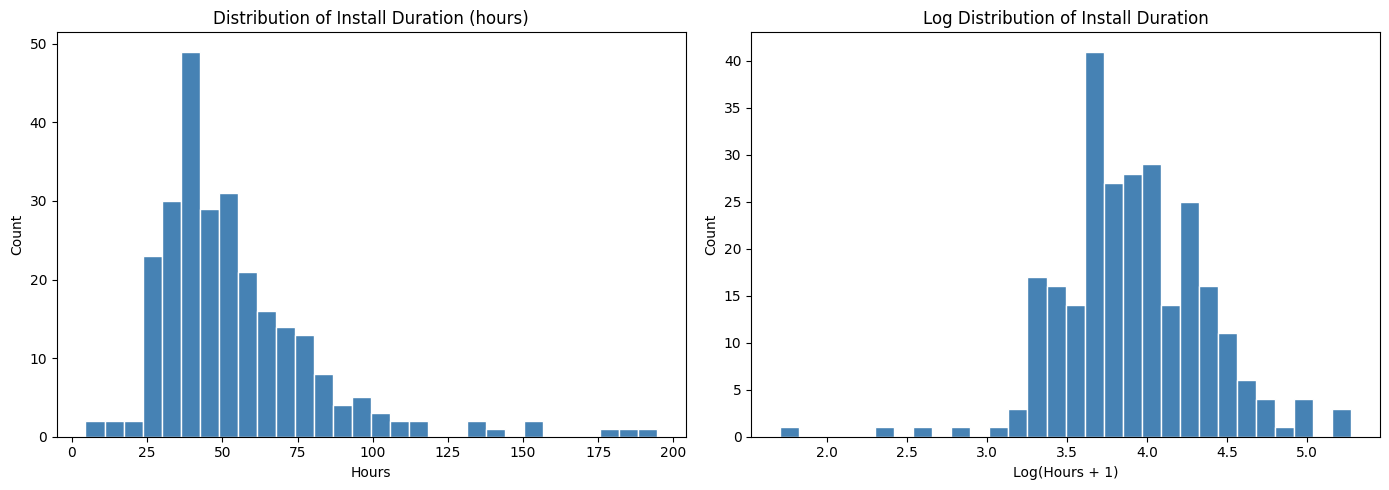

Skewness: 2.024
Outliers (>2 std): 11


In [5]:
# Target distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df['Estimated Total Direct Time'].dropna(), bins=30, color='steelblue', edgecolor='white')
axes[0].set_title('Distribution of Install Duration (hours)')
axes[0].set_xlabel('Hours')
axes[0].set_ylabel('Count')
axes[1].hist(np.log1p(df['Estimated Total Direct Time'].dropna()), bins=30, color='steelblue', edgecolor='white')
axes[1].set_title('Log Distribution of Install Duration')
axes[1].set_xlabel('Log(Hours + 1)')
axes[1].set_ylabel('Count')
plt.tight_layout()
plt.show()
print('Skewness:', round(df['Estimated Total Direct Time'].skew(), 3))
print('Outliers (>2 std):', (np.abs(df['Estimated Total Direct Time'] - df['Estimated Total Direct Time'].mean()) > 2 * df['Estimated Total Direct Time'].std()).sum())

In [6]:
# Numeric correlations with target
numeric_cols = ['Panel QTY', 'Tilt', 'Azimuth', 'System Rating (kW DC)',
                '# of Arrays', '# of reinforcement', '# of Stories',
                'Module Length', 'Module Width', 'Module Weight',
                'Estimated Total # of People on Site']
corrs = df[numeric_cols + ['Estimated Total Direct Time']].corr()['Estimated Total Direct Time'].drop('Estimated Total Direct Time')
print('Correlations with Install Duration:')
print(corrs.sort_values(ascending=False).round(4))

Correlations with Install Duration:
System Rating (kW DC)                  0.6525
Panel QTY                              0.6403
# of Arrays                            0.3727
Estimated Total # of People on Site    0.3527
# of Stories                           0.1990
# of reinforcement                     0.1801
Module Weight                          0.1402
Module Width                           0.0572
Module Length                          0.0349
Tilt                                   0.0189
Azimuth                               -0.0142
Name: Estimated Total Direct Time, dtype: float64


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


...

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


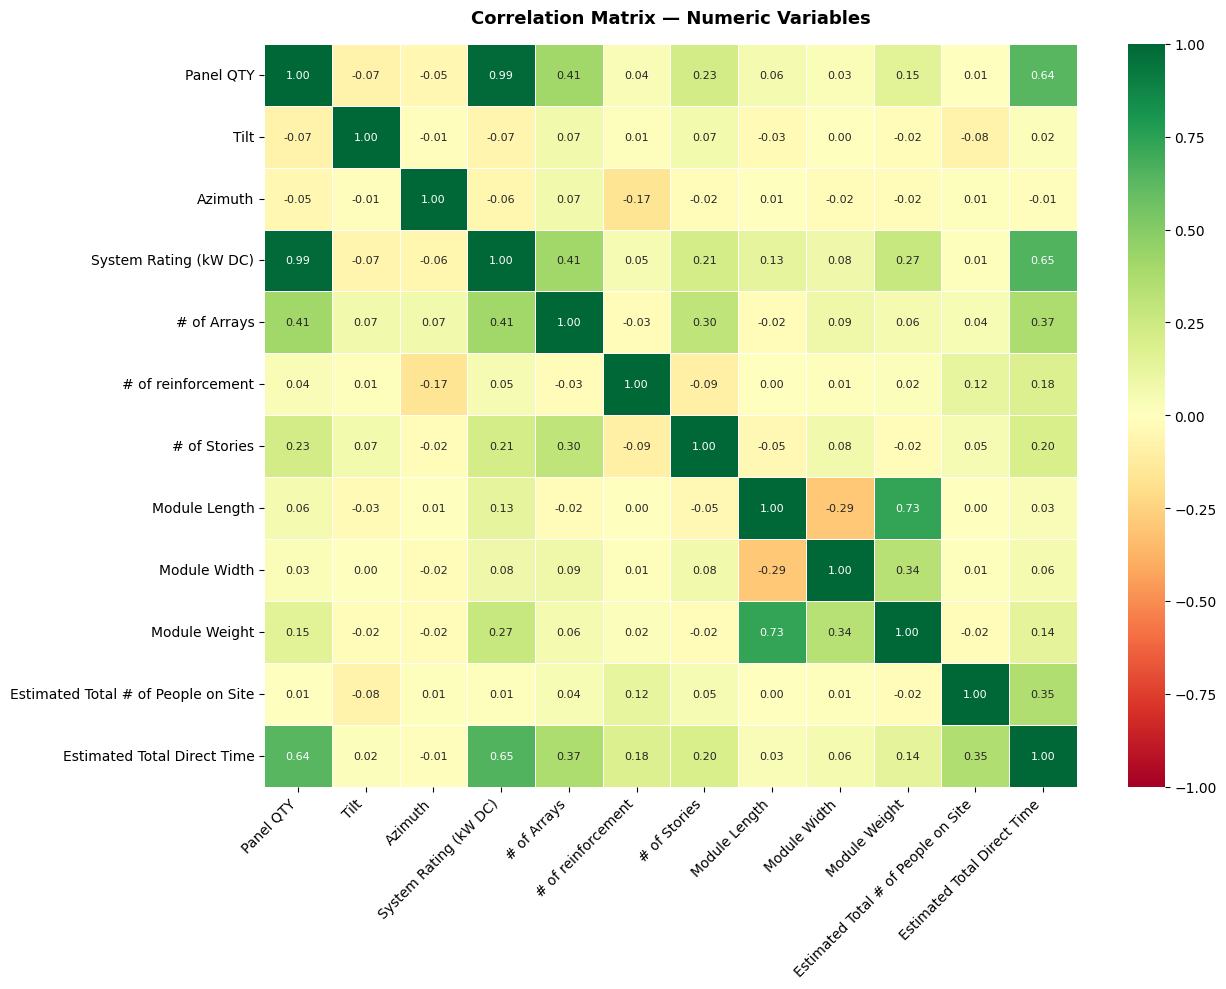

In [7]:
# Correlation heatmap
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(
    df[numeric_cols + ['Estimated Total Direct Time']].corr(),
    annot=True, fmt='.2f', cmap='RdYlGn', center=0,
    vmin=-1, vmax=1, linewidths=0.5, linecolor='white',
    ax=ax, annot_kws={'size': 8}
)
ax.set_title('Correlation Matrix — Numeric Variables', fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


...

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


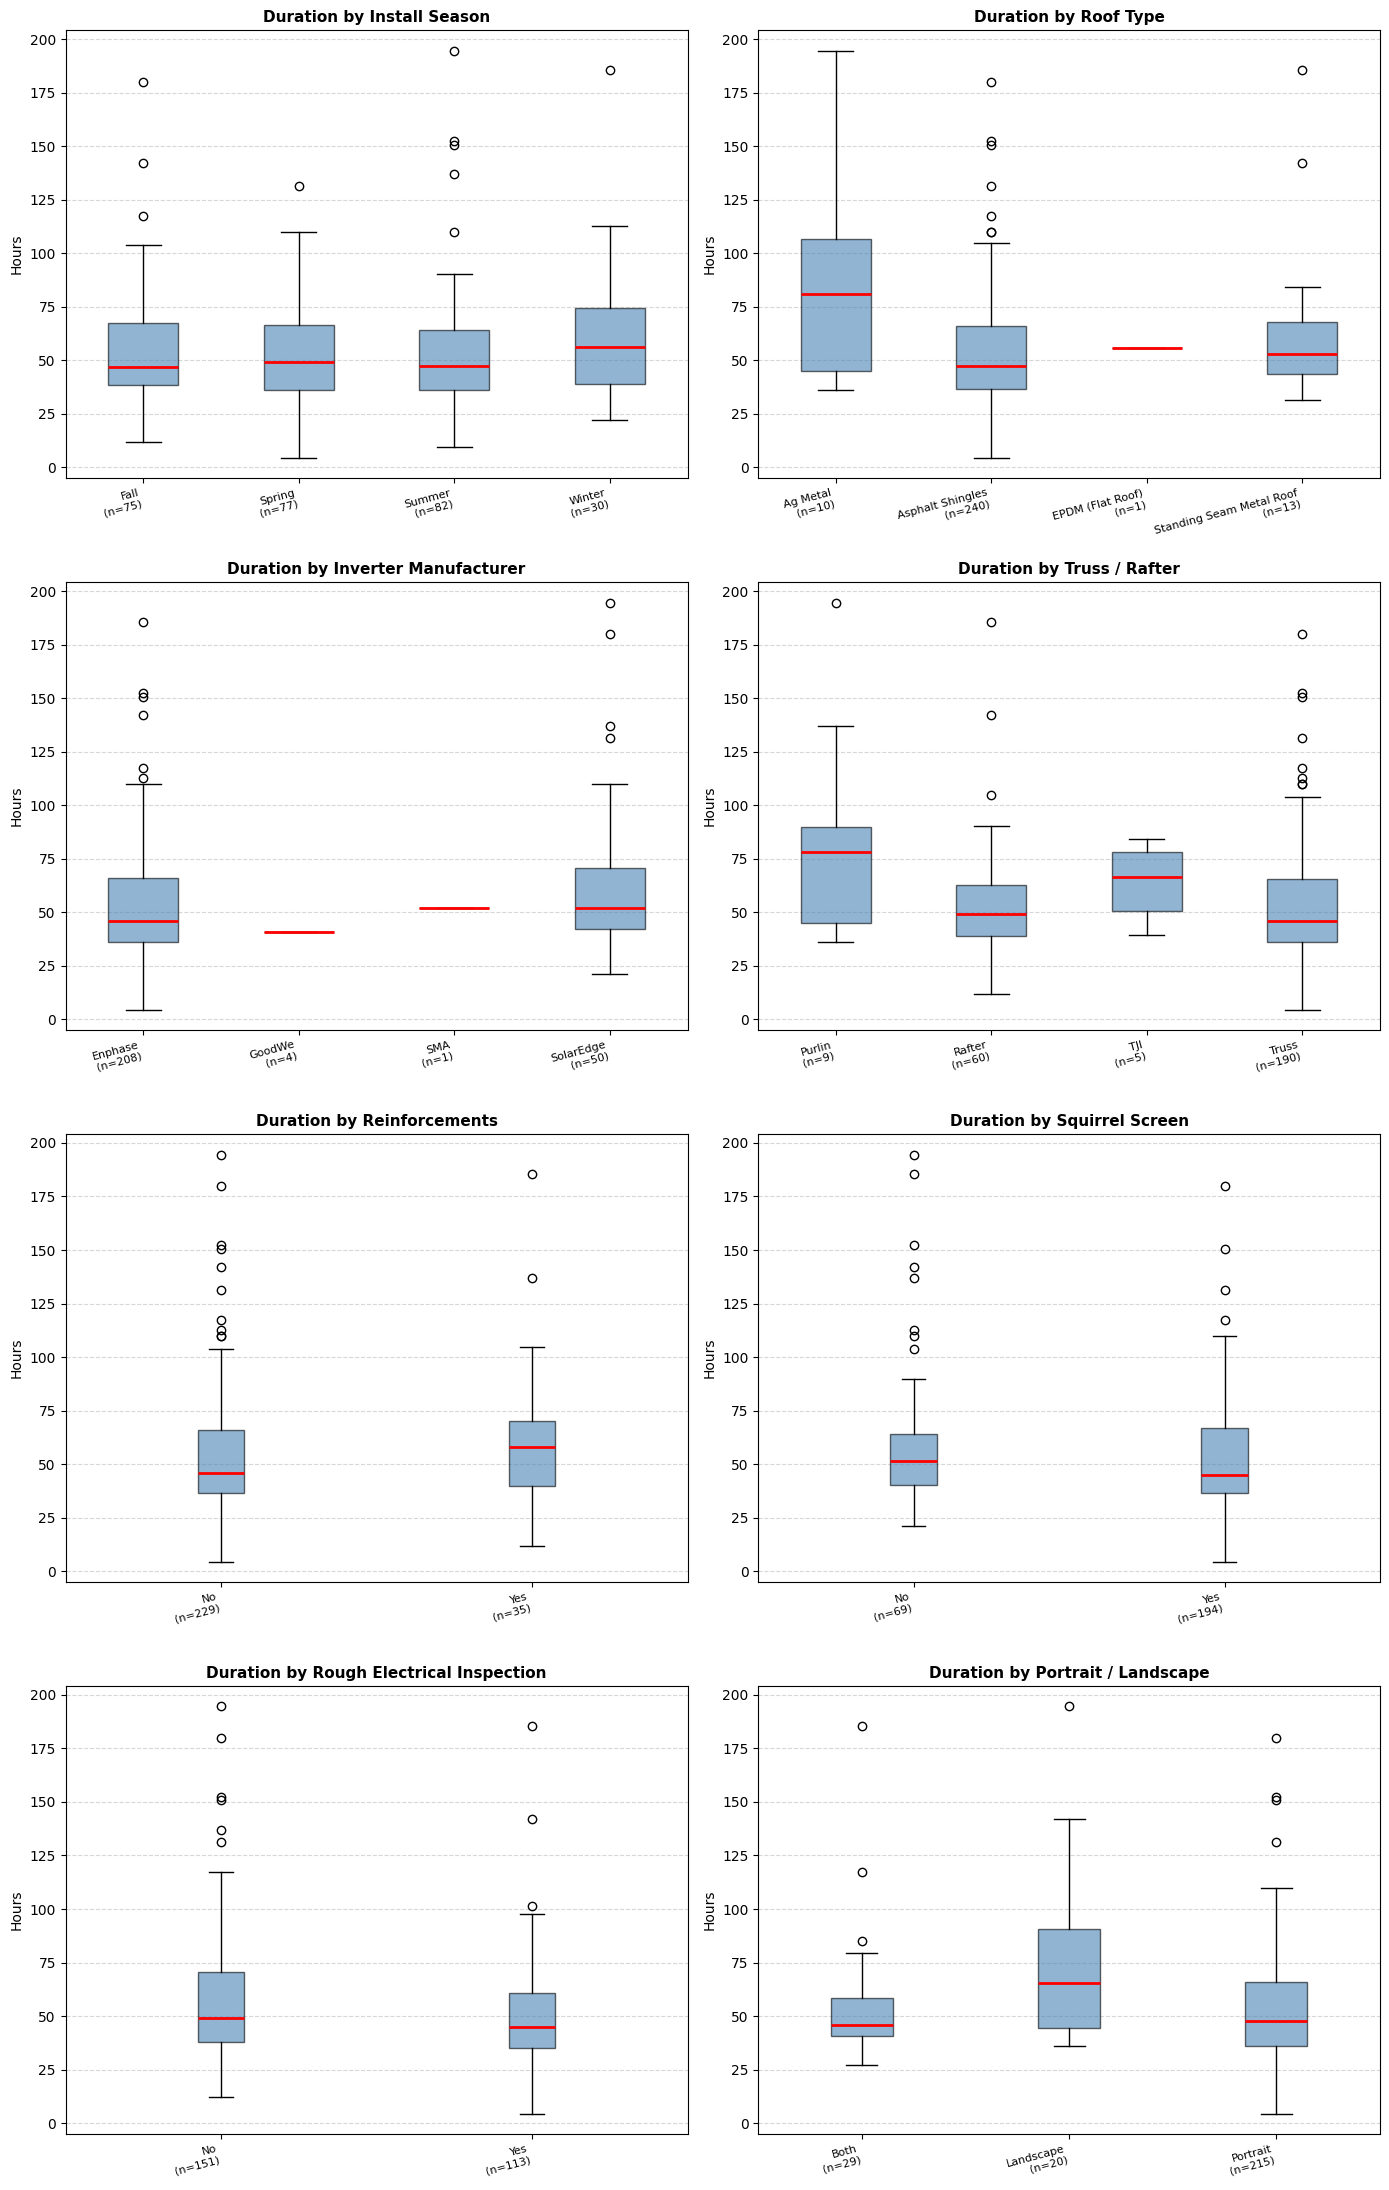

In [8]:
# Categorical breakdowns — box plots
cat_cols = ['Install Season', 'Roof Type', 'Inverter Manufacturer',
            'Truss / Rafter', 'Reinforcements', 'Squirrel Screen',
            'Rough Electrical Inspection', 'Portrait / Landscape']

fig, axes = plt.subplots(4, 2, figsize=(14, 22))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    groups = [grp['Estimated Total Direct Time'].dropna().values
              for _, grp in df.groupby(col)]
    labels = [str(k) for k in df.groupby(col).groups.keys()]
    counts = [df[df[col] == k].shape[0] for k in df.groupby(col).groups.keys()]

    bp = axes[i].boxplot(groups, patch_artist=True, medianprops=dict(color='red', linewidth=2))
    for patch in bp['boxes']:
        patch.set_facecolor('steelblue')
        patch.set_alpha(0.6)

    axes[i].set_xticks(range(1, len(labels) + 1))
    axes[i].set_xticklabels(
        [f'{l}\n(n={c})' for l, c in zip(labels, counts)],
        fontsize=8, rotation=15, ha='right'
    )
    axes[i].set_title(f'Duration by {col}', fontsize=11, fontweight='bold')
    axes[i].set_ylabel('Hours')
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


...

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


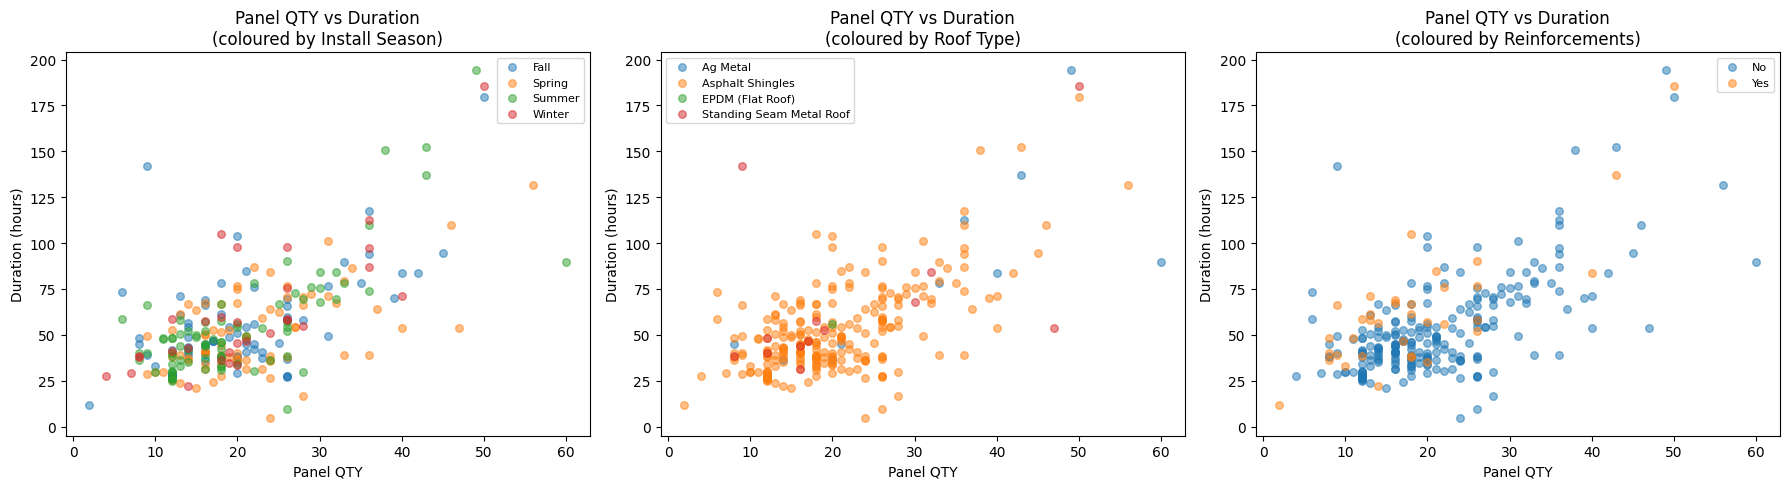

In [9]:
# Panel QTY vs Duration coloured by key categoricals
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, ['Install Season', 'Roof Type', 'Reinforcements']):
    for label, group in df.groupby(col):
        ax.scatter(group['Panel QTY'], group['Estimated Total Direct Time'],
                   label=label, alpha=0.5, s=30)
    ax.set_title(f'Panel QTY vs Duration\n(coloured by {col})')
    ax.set_xlabel('Panel QTY')
    ax.set_ylabel('Duration (hours)')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## 3. Feature Engineering
Linear regression assumes straight-line relationships. We can create new features to capture curves and interactions between variables.

In [10]:
df_eng = df.copy()

# Panels per array — density/complexity per section
df_eng['Panels per Array'] = df_eng['Panel QTY'] / df_eng['# of Arrays'].replace(0, 1)

# Panels per worker — individual workload
df_eng['Panels per Worker'] = df_eng['Panel QTY'] / df_eng['Estimated Total # of People on Site'].replace(0, 1)

# Panel QTY squared — non-linear scaling
df_eng['Panel QTY^2'] = df_eng['Panel QTY'] ** 2

# Interaction: panels x arrays
df_eng['Panel QTY x Arrays'] = df_eng['Panel QTY'] * df_eng['# of Arrays']

# System size per worker
df_eng['kW per Worker'] = df_eng['System Rating (kW DC)'] / df_eng['Estimated Total # of People on Site'].replace(0, 1)

eng_features = ['Panels per Array', 'Panels per Worker', 'Panel QTY^2', 'Panel QTY x Arrays', 'kW per Worker']
corrs_eng = df_eng[eng_features + ['Estimated Total Direct Time']].corr()['Estimated Total Direct Time'].drop('Estimated Total Direct Time')
print('Engineered feature correlations with duration:')
print(corrs_eng.sort_values(ascending=False).round(4))

Engineered feature correlations with duration:
Panel QTY^2           0.6707
Panel QTY x Arrays    0.5594
kW per Worker         0.3521
Panels per Worker     0.3313
Panels per Array      0.2593
Name: Estimated Total Direct Time, dtype: float64


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


...

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


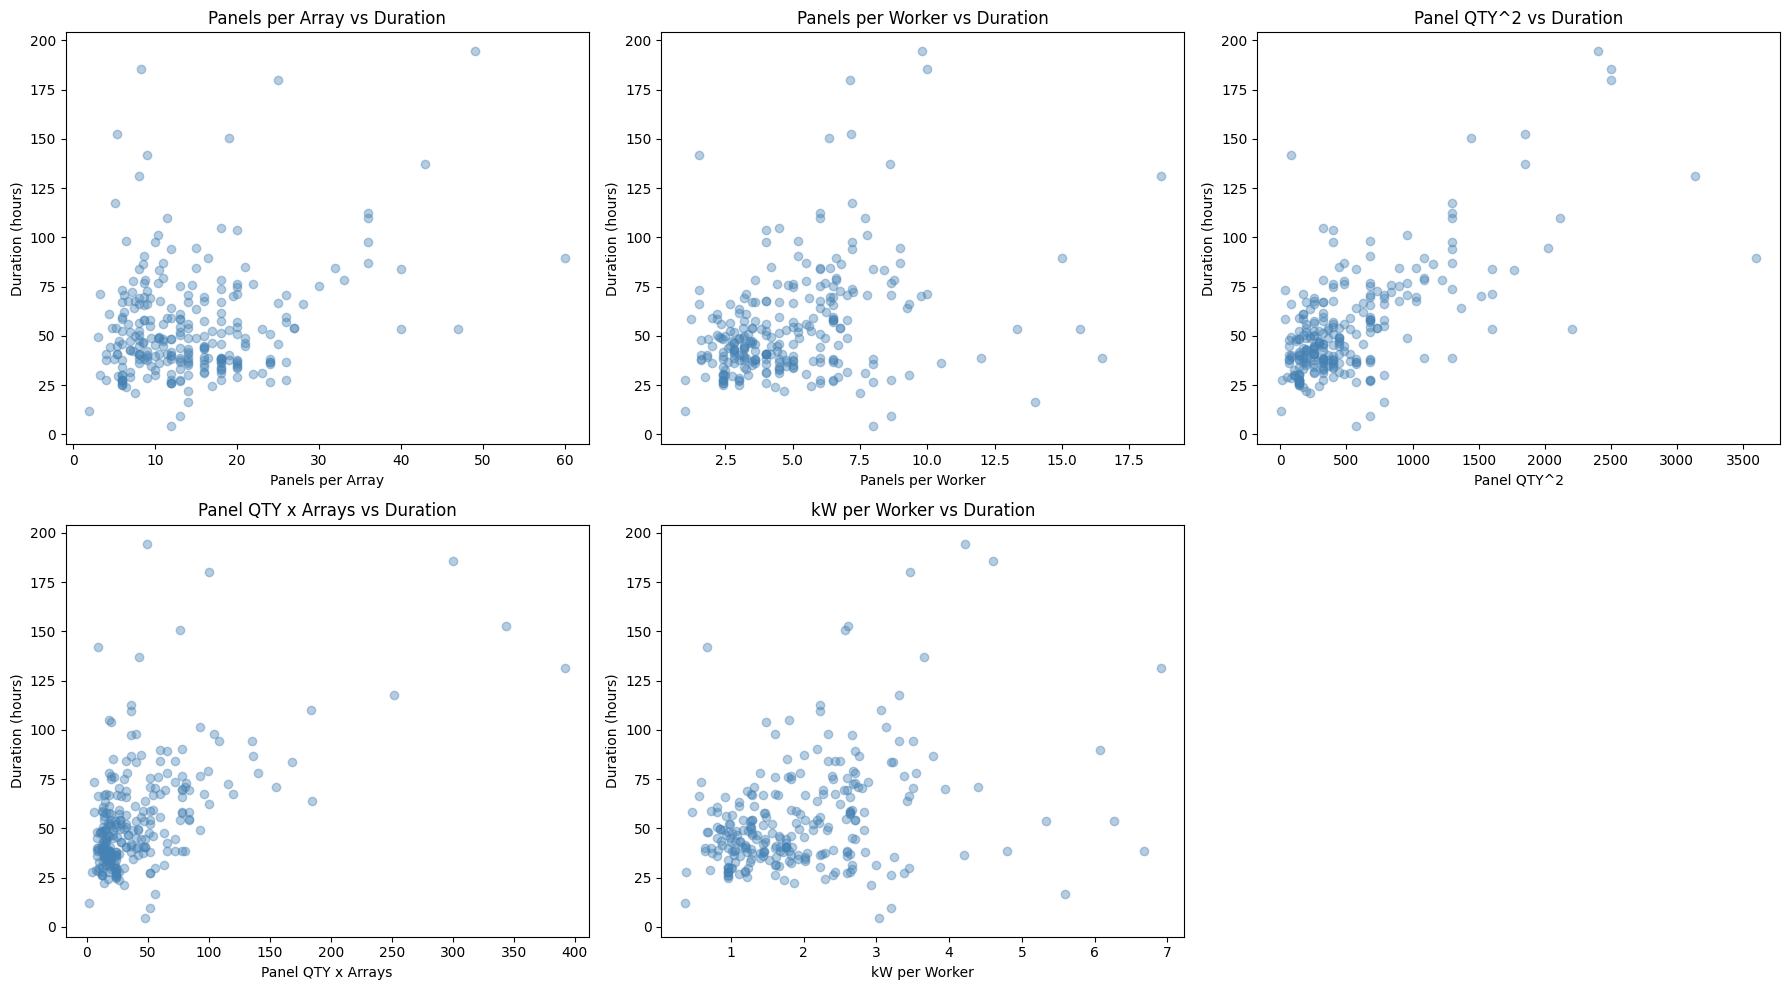

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(eng_features):
    axes[i].scatter(df_eng[col], df_eng['Estimated Total Direct Time'], alpha=0.4, color='steelblue')
    axes[i].set_title(f'{col} vs Duration')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Duration (hours)')

axes[len(eng_features)].axis('off')
plt.tight_layout()
plt.show()

## 4. Model Comparison

- **Linear Regression** — baseline
- **Ridge** — linear with regularization (reduces overfitting)
- **Lasso** — like Ridge, also removes weak features automatically
- **Random Forest** — ensemble of decision trees, handles non-linear relationships
- **Gradient Boosting** — sequential trees, typically strongest on tabular data

In [12]:
def build_features(dataframe, include_engineered=False):
    X = dataframe[['Panel QTY', 'Estimated Total # of People on Site', '# of Arrays',
                    'System Rating (kW DC)', '# of Stories']].copy()
    X = pd.concat([X,
        pd.get_dummies(dataframe['Install Season'], prefix='Season', drop_first=True),
        pd.get_dummies(dataframe['Roof Type'], prefix='Roof', drop_first=True),
        pd.get_dummies(dataframe['Reinforcements'], prefix='Reinforce', drop_first=True),
        pd.get_dummies(dataframe['Squirrel Screen'], prefix='Squirrel', drop_first=True),
    ], axis=1)
    if include_engineered:
        X['Panels per Array']    = dataframe['Panel QTY'] / dataframe['# of Arrays'].replace(0, 1)
        X['Panels per Worker']   = dataframe['Panel QTY'] / dataframe['Estimated Total # of People on Site'].replace(0, 1)
        X['Panel QTY^2']         = dataframe['Panel QTY'] ** 2
        X['Panel QTY x Arrays']  = dataframe['Panel QTY'] * dataframe['# of Arrays']
        X['kW per Worker']       = dataframe['System Rating (kW DC)'] / dataframe['Estimated Total # of People on Site'].replace(0, 1)
    return X.apply(pd.to_numeric, errors='coerce')

y = df_eng['Estimated Total Direct Time']
X_base = build_features(df_eng, include_engineered=False)
X_eng  = build_features(df_eng, include_engineered=True)

mask_base = X_base.notna().all(axis=1) & y.notna()
mask_eng  = X_eng.notna().all(axis=1) & y.notna()

print('Base features:', list(X_base.columns))
print('\nEngineered features added:', [c for c in X_eng.columns if c not in X_base.columns])

Base features: ['Panel QTY', 'Estimated Total # of People on Site', '# of Arrays', 'System Rating (kW DC)', '# of Stories', 'Season_Spring', 'Season_Summer', 'Season_Winter', 'Roof_Asphalt Shingles', 'Roof_EPDM (Flat Roof)', 'Roof_Standing Seam Metal Roof', 'Reinforce_Yes', 'Squirrel_Yes']

Engineered features added: ['Panels per Array', 'Panels per Worker', 'Panel QTY^2', 'Panel QTY x Arrays', 'kW per Worker']


In [13]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    'Linear Regression':  LinearRegression(),
    'Ridge':              Ridge(alpha=1.0),
    'Lasso':              Lasso(alpha=1.0),
    'Random Forest':      RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE),
    'Gradient Boosting':  GradientBoostingRegressor(n_estimators=100, random_state=RANDOM_STATE),
}

results = []
for name, m in models.items():
    for X_set, label, mask in [
        (X_base, 'Base', mask_base),
        (X_eng,  'Engineered', mask_eng)
    ]:
        X_c, y_c = X_set[mask], y[mask]
        scores = cross_val_score(m, X_c, y_c, cv=kf, scoring='r2')
        results.append({'Model': name, 'Features': label,
                        'Mean R²': round(scores.mean(), 4),
                        'Std R²': round(scores.std(), 4),
                        'Min R²': round(scores.min(), 4),
                        'Max R²': round(scores.max(), 4)})

results_df = pd.DataFrame(results).sort_values('Mean R²', ascending=False)
results_df

,Model,Features,Mean R²,Std R²,Min R²,Max R²
1,Linear Regression,Engineered,0.5372,0.1666,0.3564,0.8106
3,Ridge,Engineered,0.5307,0.1597,0.3521,0.7867
6,Random Forest,Base,0.5277,0.1159,0.4274,0.7472
5,Lasso,Engineered,0.5187,0.1531,0.3600,0.7774
2,Ridge,Base,0.5178,0.1220,0.3538,0.7194
8,Gradient Boosting,Base,0.5144,0.1356,0.3798,0.7545
0,Linear Regression,Base,0.5112,0.1229,0.3509,0.7136
4,Lasso,Base,0.5077,0.1095,0.3591,0.6964
7,Random Forest,Engineered,0.5050,0.0957,0.4125,0.6876
9,Gradient Boosting,Engineered,0.4633,0.1237,0.3398,0.6972


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


...

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


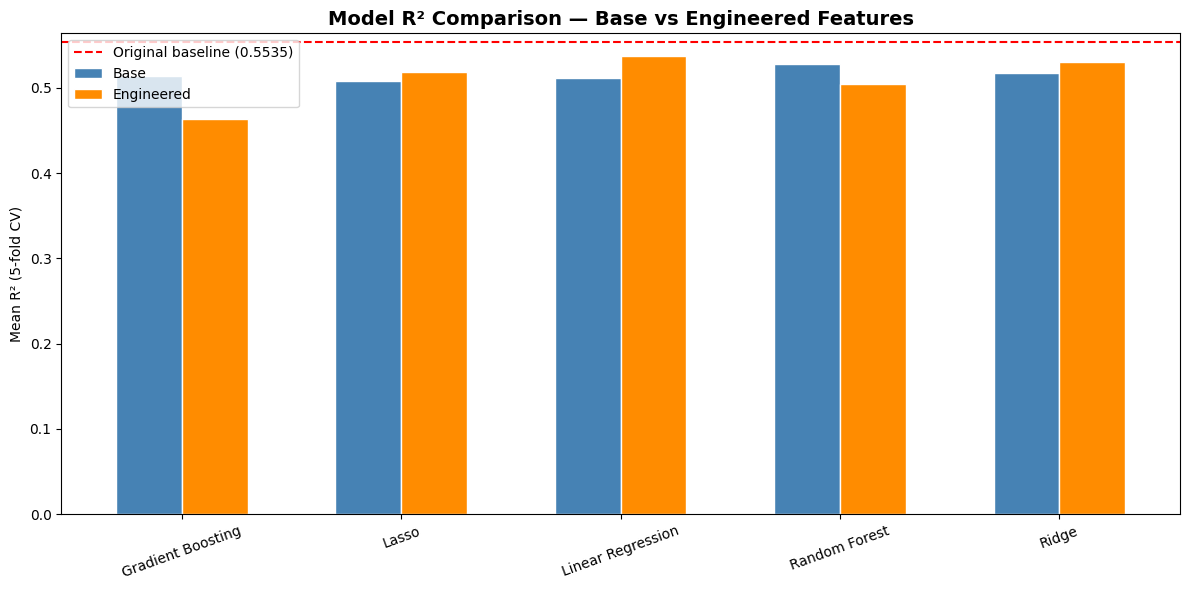

In [14]:
fig, ax = plt.subplots(figsize=(12, 6))
pivot = results_df.drop_duplicates(subset=['Model', 'Features']).pivot_table(index='Model', columns='Features', values='Mean R²', aggfunc='mean')
pivot.plot(kind='bar', ax=ax, color=['steelblue', 'darkorange'], edgecolor='white', width=0.6)
ax.set_title('Model R² Comparison — Base vs Engineered Features', fontsize=14, fontweight='bold')
ax.set_ylabel('Mean R² (5-fold CV)')
ax.set_xlabel('')
ax.axhline(0.5535, color='red', linestyle='--', linewidth=1.5, label='Original baseline (0.5535)')
ax.legend()
ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

## 5. Residual Analysis
Fit the best model on a train/test split and examine where predictions go wrong.

In [15]:
best_name = results_df.iloc[0]['Model']
best_features = results_df.iloc[0]['Features']
print(f'Best model: {best_name} ({best_features} features)')

X_best = X_eng[mask_eng] if best_features == 'Engineered' else X_base[mask_base]
y_best = y[mask_eng if best_features == 'Engineered' else mask_base]

X_train, X_test, y_train, y_test = train_test_split(X_best, y_best, test_size=0.2, random_state=RANDOM_STATE)

best_model = models[best_name]
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

print(f'Test R²:   {r2_score(y_test, y_pred):.4f}')
print(f'Test RMSE: {mean_squared_error(y_test, y_pred)**0.5:.2f} hours')

Best model: Linear Regression (Engineered features)
Test R²:   0.6109
Test RMSE: 16.61 hours


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


...

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


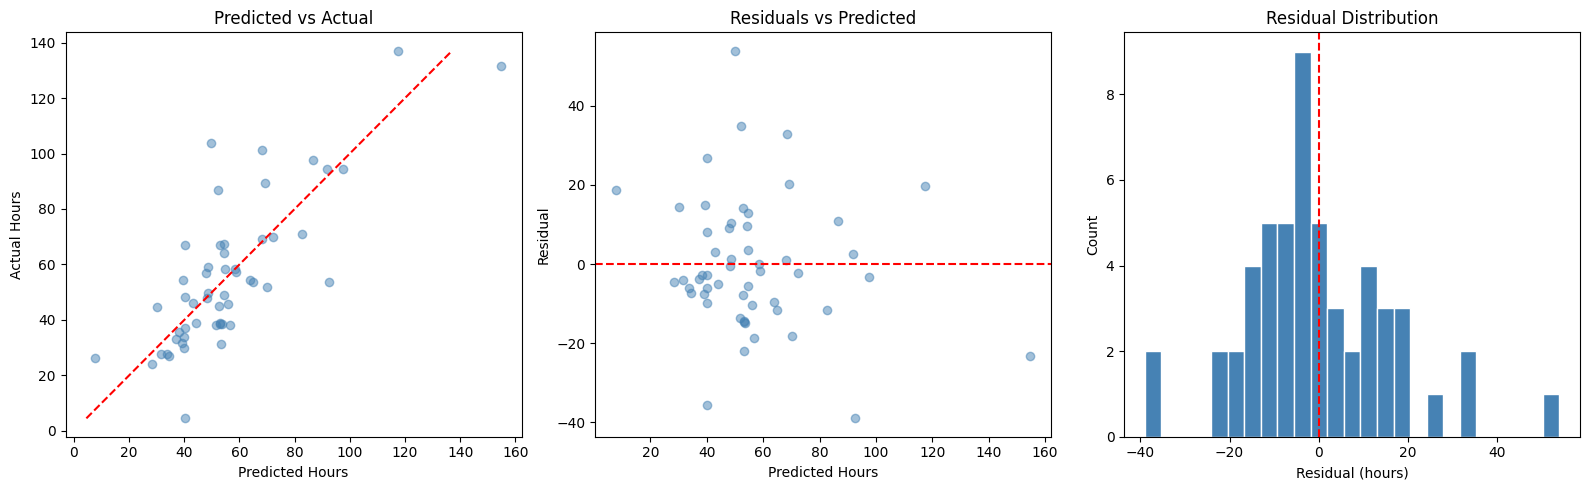

In [16]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].scatter(y_pred, y_test, alpha=0.5, color='steelblue')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=1.5)
axes[0].set_title('Predicted vs Actual')
axes[0].set_xlabel('Predicted Hours')
axes[0].set_ylabel('Actual Hours')

axes[1].scatter(y_pred, residuals, alpha=0.5, color='steelblue')
axes[1].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title('Residuals vs Predicted')
axes[1].set_xlabel('Predicted Hours')
axes[1].set_ylabel('Residual')

axes[2].hist(residuals, bins=25, color='steelblue', edgecolor='white')
axes[2].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[2].set_title('Residual Distribution')
axes[2].set_xlabel('Residual (hours)')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.show()

In [17]:
if hasattr(best_model, 'feature_importances_'):
    importances = pd.Series(best_model.feature_importances_, index=X_best.columns).sort_values(ascending=True)
    fig, ax = plt.subplots(figsize=(10, 7))
    importances.plot(kind='barh', ax=ax, color='steelblue', edgecolor='white')
    ax.set_title(f'Feature Importance — {best_name}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Importance')
    plt.tight_layout()
    plt.show()
else:
    print('Feature importance not available for linear models.')

Feature importance not available for linear models.


## 6. Best Model Summary

In [18]:
print('='*55)
print('BEST MODEL SUMMARY')
print('='*55)
print(f'\nModel:          {best_name}')
print(f'Feature set:    {best_features}')
print(f'Test R²:        {r2_score(y_test, y_pred):.4f}')
print(f'Test RMSE:      {mean_squared_error(y_test, y_pred)**0.5:.2f} hours')
print(f'\nOriginal baseline R²: 0.5535')
print(f'Improvement:          +{round(r2_score(y_test, y_pred) - 0.5535, 4)}')
print('\nTop 5 models by cross-validated R²:')
print(results_df[['Model', 'Features', 'Mean R²', 'Std R²']].head(5).to_string(index=False))
print('\nWorst predictions (largest residuals):')
residual_df = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred.round(2),
    'Error (hrs)': residuals.values.round(2),
    'Error (%)': (residuals.values / y_test.values * 100).round(1)
})
print(residual_df.reindex(residual_df['Error (hrs)'].abs().sort_values(ascending=False).index).head(10).to_string(index=False))

BEST MODEL SUMMARY

Model:          Linear Regression
Feature set:    Engineered
Test R²:        0.6109
Test RMSE:      16.61 hours

Original baseline R²: 0.5535
Improvement:          +0.0574

Top 5 models by cross-validated R²:
            Model   Features  Mean R²  Std R²
Linear Regression Engineered   0.5372  0.1666
            Ridge Engineered   0.5307  0.1597
    Random Forest       Base   0.5277  0.1159
            Lasso Engineered   0.5187  0.1531
            Ridge       Base   0.5178  0.1220

Worst predictions (largest residuals):
  Actual  Predicted  Error (hrs)  Error (%)
103.7500      49.85        53.90       51.9
 53.5000      92.47       -38.97      -72.8
  4.5000      40.20       -35.70     -793.3
 87.0000      52.17        34.83       40.0
101.2500      68.29        32.96       32.6
 67.0000      40.19        26.81       40.0
131.4000     154.73       -23.33      -17.8
 31.2500      53.21       -21.96      -70.3
 89.5000      69.34        20.16       22.5
137.0833     11

## 7. Production Model — Interaction Term Validation
Compare the production model (Panel QTY + Crew + Arrays + Season) against the same model
plus a **Panel QTY × Crew Size** interaction. Averaged over 10 random seeds to reduce split noise.

In [19]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
import numpy as np

TARGET = 'Estimated Total Direct Time'
SEASON = 'Install Season'

def build_production_features(dataframe, interaction=False):
    """Mirrors the production model.py feature set."""
    X = dataframe[['Panel QTY', 'Estimated Total # of People on Site', '# of Arrays']].copy()
    X = pd.concat([
        X,
        pd.get_dummies(dataframe[SEASON], prefix=SEASON, drop_first=True)
    ], axis=1).apply(pd.to_numeric, errors='coerce')
    if interaction:
        X['Panel QTY x Crew Size'] = X['Panel QTY'] * X['Estimated Total # of People on Site']
    return X

y_prod = pd.to_numeric(df[TARGET], errors='coerce')
X_prod_base = build_production_features(df, interaction=False)
X_prod_int  = build_production_features(df, interaction=True)

mask_b = X_prod_base.notna().all(axis=1) & y_prod.notna()
mask_i = X_prod_int.notna().all(axis=1) & y_prod.notna()

# CV R² over 10 random seeds
n_seeds = 10
base_scores, int_scores = [], []
for seed in range(n_seeds):
    kf = KFold(n_splits=5, shuffle=True, random_state=seed)
    base_scores.extend(cross_val_score(LinearRegression(), X_prod_base[mask_b], y_prod[mask_b], cv=kf, scoring='r2'))
    int_scores.extend(cross_val_score(LinearRegression(), X_prod_int[mask_i],  y_prod[mask_i],  cv=kf, scoring='r2'))

print('5-fold CV R² averaged over 10 random seeds (50 folds total):')
print(f'  Base model (no interaction): {np.mean(base_scores):.4f}  ±{np.std(base_scores):.4f}')
print(f'  + Panel x Crew interaction:  {np.mean(int_scores):.4f}  ±{np.std(int_scores):.4f}')
print(f'  Gain: +{np.mean(int_scores) - np.mean(base_scores):.4f}')

# MAE comparison — baseline is a naive model that always predicts the training mean
cv_fixed = KFold(n_splits=5, shuffle=True, random_state=42)
mae_naive = -cross_val_score(DummyRegressor(strategy='mean'), X_prod_base[mask_b], y_prod[mask_b],
                              cv=cv_fixed, scoring='neg_mean_absolute_error')
mae_base  = -cross_val_score(LinearRegression(), X_prod_base[mask_b], y_prod[mask_b],
                              cv=cv_fixed, scoring='neg_mean_absolute_error')
mae_int   = -cross_val_score(LinearRegression(), X_prod_int[mask_i],  y_prod[mask_i],
                              cv=cv_fixed, scoring='neg_mean_absolute_error')
baseline_mae = mae_naive.mean()

print(f'\nMAE naive (predict mean):    {baseline_mae:.2f} hrs')
print(f'MAE base model:              {mae_base.mean():.2f} hrs  ({(1 - mae_base.mean()/baseline_mae)*100:.1f}% below naive)')
print(f'MAE + interaction:           {mae_int.mean():.2f} hrs  ({(1 - mae_int.mean()/baseline_mae)*100:.1f}% below naive)')


5-fold CV R² averaged over 10 random seeds (50 folds total):
  Base model (no interaction): 0.4618  ±0.1824
  + Panel x Crew interaction:  0.5016  ±0.1698
  Gain: +0.0399



MAE naive (predict mean):    19.73 hrs
MAE base model:              13.65 hrs  (30.8% below naive)
MAE + interaction:           12.93 hrs  (34.5% below naive)


### Production Model Diagnostics
Residual plots for the linear regression + interaction term on a held-out 20% test set.

Test R²:   0.5711
Test RMSE: 17.44 hrs
Test MAE:  12.53 hrs

Coefficients:
  Panel QTY                                     -1.1064
  Estimated Total # of People on Site           -2.0040
  # of Arrays                                   +2.2063
  Install Season_Spring                         +4.7135
  Install Season_Summer                         +0.7787
  Install Season_Winter                         +8.6793
  Panel QTY x Crew Size                         +0.6066
  Intercept: 23.1455


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


...

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


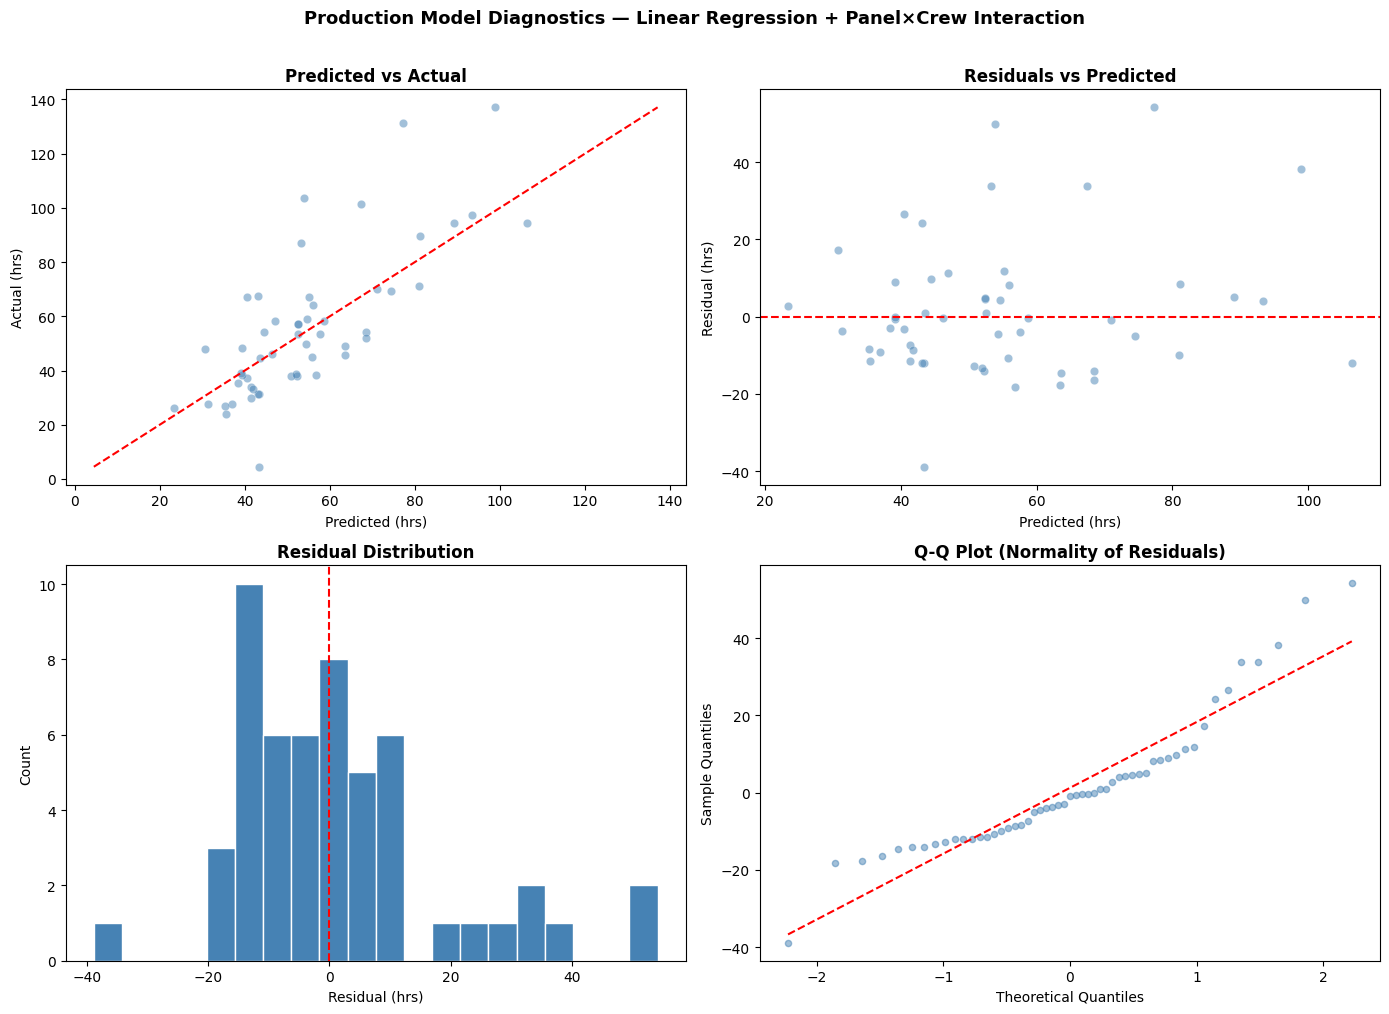

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import scipy.stats as stats

X_d = X_prod_int[mask_i]
y_d = y_prod[mask_i]

X_train, X_test, y_train, y_test = train_test_split(
    X_d, y_d, test_size=0.2, random_state=42
)

prod_model = LinearRegression()
prod_model.fit(X_train, y_train)
y_pred = prod_model.predict(X_test)
residuals = y_test - y_pred

print(f'Test R²:   {r2_score(y_test, y_pred):.4f}')
print(f'Test RMSE: {mean_squared_error(y_test, y_pred)**0.5:.2f} hrs')
print(f'Test MAE:  {np.abs(residuals).mean():.2f} hrs')
print()
print('Coefficients:')
for name, coef in zip(X_d.columns, prod_model.coef_):
    print(f'  {name:<45} {coef:+.4f}')
print(f'  Intercept: {prod_model.intercept_:.4f}')

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Predicted vs Actual
axes[0, 0].scatter(y_pred, y_test, alpha=0.5, color='steelblue', edgecolors='white', linewidth=0.3)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0, 0].plot(lims, lims, 'r--', linewidth=1.5)
axes[0, 0].set_title('Predicted vs Actual', fontweight='bold')
axes[0, 0].set_xlabel('Predicted (hrs)')
axes[0, 0].set_ylabel('Actual (hrs)')

# Residuals vs Predicted
axes[0, 1].scatter(y_pred, residuals, alpha=0.5, color='steelblue', edgecolors='white', linewidth=0.3)
axes[0, 1].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0, 1].set_title('Residuals vs Predicted', fontweight='bold')
axes[0, 1].set_xlabel('Predicted (hrs)')
axes[0, 1].set_ylabel('Residual (hrs)')

# Residual distribution
axes[1, 0].hist(residuals, bins=20, color='steelblue', edgecolor='white')
axes[1, 0].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[1, 0].set_title('Residual Distribution', fontweight='bold')
axes[1, 0].set_xlabel('Residual (hrs)')
axes[1, 0].set_ylabel('Count')

# Q-Q plot
(osm, osr), (slope, intercept, r) = stats.probplot(residuals, dist='norm')
axes[1, 1].scatter(osm, osr, alpha=0.5, color='steelblue', s=20)
axes[1, 1].plot(osm, slope * np.array(osm) + intercept, 'r--', linewidth=1.5)
axes[1, 1].set_title('Q-Q Plot (Normality of Residuals)', fontweight='bold')
axes[1, 1].set_xlabel('Theoretical Quantiles')
axes[1, 1].set_ylabel('Sample Quantiles')

plt.suptitle('Production Model Diagnostics — Linear Regression + Panel×Crew Interaction',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()